<a href="https://colab.research.google.com/github/abusaleh917/Practice/blob/main/coference_paper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Dataset Load

In [2]:
#Install boosting libraries
!pip install xgboost lightgbm catboost -q

In [3]:
#Lode libraries
#core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#preprocessing and model selection
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

#Ensemble Models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score,
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 20   # same seed everywhere -> reproducible results


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks_Data_Science/UAVIDS-2025.csv')
df.head()

,FlowID,FlowDuration/s,SrcAddr,SrcPort,DstAddr,DstPort,Protocol,TxPackets,RxPackets,LostPackets,...,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount,label
0,1,175.007,192.168.0.150,9,192.168.0.16,9,UDP,251,215,36,...,1.22853,109.002,93.3679,0.022152,0.024406,0.746943,76,0.143426,0.074419,Sybil Attack
1,2,175.008,192.168.0.150,9,192.168.0.19,9,UDP,251,223,28,...,1.27423,109.001,96.8411,0.019637,0.018678,0.774729,76,0.111554,0.053812,Sybil Attack
2,3,175.010,192.168.0.150,9,192.168.0.24,9,UDP,251,224,27,...,1.27993,108.999,97.2744,0.023701,0.023917,0.778195,76,0.107570,0.044643,Sybil Attack
3,4,175.014,192.168.0.150,9,192.168.0.34,9,UDP,251,212,39,...,1.21133,108.997,92.0614,0.034014,0.025408,0.736491,76,0.155378,0.033019,Sybil Attack
4,5,175.017,192.168.0.150,9,192.168.0.39,9,UDP,251,215,36,...,1.22845,108.995,93.3623,0.034396,0.024933,0.746899,76,0.143426,0.009302,Sybil Attack


In [6]:
#column type and missing value
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122171 entries, 0 to 122170
Data columns (total 23 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   FlowID           122171 non-null  int64  
 1   FlowDuration/s   122171 non-null  float64
 2   SrcAddr          122171 non-null  object 
 3   SrcPort          122171 non-null  int64  
 4   DstAddr          122171 non-null  object 
 5   DstPort          122171 non-null  int64  
 6   Protocol         122171 non-null  object 
 7   TxPackets        122171 non-null  int64  
 8   RxPackets        122171 non-null  int64  
 9   LostPackets      122171 non-null  int64  
 10  TxBytes          122171 non-null  int64  
 11  RxBytes          122171 non-null  int64  
 12  TxPacketRate/s   122171 non-null  float64
 13  RxPacketRate/s   122171 non-null  float64
 14  TxByteRate/s     122171 non-null  float64
 15  RxByteRate/s     122171 non-null  float64
 16  MeanDelay/s      122171 non-null  floa

In [7]:
# Summary statistics of numeric columns
df.describe()

,FlowID,FlowDuration/s,SrcPort,DstPort,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
count,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,1.221710e+05,1.221710e+05,122171.000000,122171.000000,1.221710e+05,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000
mean,61086.000000,696.714475,169.137348,169.137348,486.930368,426.070737,60.436159,3.587245e+04,3.193820e+04,2.466915,1.383054,1.820916e+02,103.422636,0.207858,0.140080,0.827381,68.122885,0.369328,0.264616
std,35267.874206,780.052068,278.648982,278.648982,1933.094801,1367.693106,1149.330904,1.246644e+05,1.025546e+05,130.044753,58.987416,9.857745e+03,4481.638475,0.454055,0.306921,35.853110,13.838427,0.309535,0.653093
min,1.000000,0.000076,9.000000,9.000000,1.000000,0.000000,0.000000,3.000000e+01,0.000000e+00,0.001197,0.000000,4.467260e-02,0.000000,0.000000,0.000000,0.000000,30.000000,0.000000,0.000000
25%,30543.500000,124.722000,9.000000,9.000000,14.000000,5.000000,4.000000,9.820000e+02,3.800000e+02,0.045725,0.017262,3.015870e+00,1.087125,0.019264,0.007475,0.008697,76.000000,0.090909,0.000000
50%,61086.000000,227.867000,9.000000,9.000000,51.000000,23.000000,12.000000,2.964000e+03,1.376000e+03,0.205224,0.068020,1.381560e+01,3.957470,0.058348,0.043962,0.031660,76.000000,0.285714,0.028815
75%,91628.500000,1415.655000,9.000000,9.000000,280.000000,196.000000,50.000000,1.877200e+04,1.413600e+04,1.430270,1.255630,1.086920e+02,95.359300,0.196488,0.138670,0.762875,76.000000,0.642857,0.187500
max,122171.000000,10591.800000,654.000000,654.000000,220886.000000,63653.000000,212557.000000,1.126508e+07,3.246018e+06,33116.600000,13115.800000,2.516860e+06,996800.000000,10.168500,6.717600,7974.400000,76.000000,1.333330,58.000000


In [8]:
# Print the distribution of the target variable to see the different attack / normal classes
class_counts = df['label'].value_counts()
display(class_counts.to_frame())

,count
label,
Normal Traffic,26172
Blackhole Attack,26110
Wormhole Attack,26086
Sybil Attack,24077
Flooding Attack,19726


In [9]:
# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Duplicate feature records
X = df.drop(columns=['label'])

print(
    "Duplicate feature rows:",
    X.duplicated().sum()
)

Exact duplicate rows: 0
Duplicate feature rows: 0


In [10]:
identifier_cols = [
    "FlowID",
    "SrcAddr",
    "DstAddr",
    "SrcPort",
    "DstPort"
]

for col in identifier_cols:
    if col in df.columns:
        print(
            col,
            "Unique values:",
            df[col].nunique(),
            "Total values:",
            len(df)
        )

FlowID Unique values: 122171 Total values: 122171
SrcAddr Unique values: 176 Total values: 122171
DstAddr Unique values: 218 Total values: 122171
SrcPort Unique values: 2 Total values: 122171
DstPort Unique values: 2 Total values: 122171


In [11]:
print(pd.crosstab(df["SrcPort"], df['label']))

print(pd.crosstab(
    df["SrcPort"],
    df['label'],
    normalize="index"
).round(3))

print(pd.crosstab(
    df["DstPort"],
    df['label'],
    normalize="index"
).round(3))

label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
SrcPort                                                                    
9                   11248            19726           11294         24077   
654                 14862                0           14878             0   

label    Wormhole Attack  
SrcPort                   
9                  25494  
654                  592  
label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
SrcPort                                                                    
9                   0.122            0.215           0.123         0.262   
654                 0.490            0.000           0.491         0.000   

label    Wormhole Attack  
SrcPort                   
9                  0.278  
654                0.020  
label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
DstPort                                                                    
9                   0.

In [12]:
# Define the columns to exclude from features
exclude_cols = ['FlowID', 'DstPort', 'label']

# Prepare features (X) and target (y)
X = df.drop(columns=[col for col in exclude_cols if col in df.columns])
y = df['label']

# Display shapes and heads
print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())

X shape: (122171, 20)
y shape: (122171,)


,FlowDuration/s,SrcAddr,SrcPort,DstAddr,Protocol,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
0,175.007,192.168.0.150,9,192.168.0.16,UDP,251,215,36,19076,16340,1.43423,1.22853,109.002,93.3679,0.022152,0.024406,0.746943,76,0.143426,0.074419
1,175.008,192.168.0.150,9,192.168.0.19,UDP,251,223,28,19076,16948,1.43422,1.27423,109.001,96.8411,0.019637,0.018678,0.774729,76,0.111554,0.053812
2,175.010,192.168.0.150,9,192.168.0.24,UDP,251,224,27,19076,17024,1.43420,1.27993,108.999,97.2744,0.023701,0.023917,0.778195,76,0.107570,0.044643
3,175.014,192.168.0.150,9,192.168.0.34,UDP,251,212,39,19076,16112,1.43417,1.21133,108.997,92.0614,0.034014,0.025408,0.736491,76,0.155378,0.033019
4,175.017,192.168.0.150,9,192.168.0.39,UDP,251,215,36,19076,16340,1.43415,1.22845,108.995,93.3623,0.034396,0.024933,0.746899,76,0.143426,0.009302


In [13]:
# Perform 80:20 stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Output split sizes and class distributions to verify stratification
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print("\nTrain class distribution (relative):\n", y_train.value_counts(normalize=True).round(4))
print("\nTest class distribution (relative):\n", y_test.value_counts(normalize=True).round(4))

X_train shape: (97736, 20)
X_test shape: (24435, 20)

Train class distribution (relative):
 label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1971
Flooding Attack     0.1615
Name: proportion, dtype: float64

Test class distribution (relative):
 label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1971
Flooding Attack     0.1614
Name: proportion, dtype: float64


In [14]:
# Identify categorical columns to encode
categorical_cols = ['SrcAddr', 'DstAddr', 'Protocol']

# Encode categorical columns using LabelEncoder
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    # Fit on training data and transform both train and test sets
    # Using map / handling unseen values dynamically if necessary, but fit/transform is standard
    X_train[col] = le.fit_transform(X_train[col].astype(str))

    # For test set, mapping unseen labels to a placeholder if any exist
    # (Normally we can use a lookup dictionary or map)
    le_dict = dict(zip(le.classes_, le.transform(le.classes_)))
    X_test[col] = X_test[col].astype(str).map(le_dict).fillna(-1).astype(int)

    label_encoders[col] = le

# Also encode the target labels (y) to integers for models that require numeric classes
target_encoder = LabelEncoder()
y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

print("Encoded target classes mapping:")
for idx, class_name in enumerate(target_encoder.classes_):
    print(f"{class_name} -> {idx}")

# Display a preview of the processed features
display(X_train.head())

Encoded target classes mapping:
Blackhole Attack -> 0
Flooding Attack -> 1
Normal Traffic -> 2
Sybil Attack -> 3
Wormhole Attack -> 4


,FlowDuration/s,SrcAddr,SrcPort,DstAddr,Protocol,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
52894,167.4040,64,9,171,0,434,401,33,32984,30476,2.592530,2.395410,197.033000,182.051000,0.038459,0.040258,1.456410,76,0.076037,0.004988
64535,1777.1300,96,654,74,0,34,34,0,1552,1552,0.019132,0.019132,0.873316,0.873316,0.005040,0.005514,0.006987,45,0.000000,0.000000
105035,195.0050,14,9,176,0,54,22,32,4104,1672,0.276917,0.112818,21.045700,8.574160,0.160881,0.123222,0.068593,76,0.592593,0.000000
40980,72.4056,160,9,193,0,11,5,6,836,380,0.151922,0.069055,11.546100,5.248210,0.349227,0.266044,0.041986,76,0.545455,0.400000
105343,195.2100,38,9,146,0,55,13,42,4180,988,0.281748,0.066595,21.412800,5.061220,0.378091,0.383907,0.040490,76,0.763636,0.076923


In [15]:
# Initialize Extra Trees Classifier
et_model = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Train the model
et_model.fit(X_train, y_train_encoded)

# Predict on test set
y_pred_et = et_model.predict(X_test)

# Generate classification report
print("--- Extra Trees Classification Report ---")
print(classification_report(y_test_encoded, y_pred_et, target_names=target_encoder.classes_))

--- Extra Trees Classification Report ---
                  precision    recall  f1-score   support

Blackhole Attack       0.93      0.88      0.90      5222
 Flooding Attack       1.00      1.00      1.00      3945
  Normal Traffic       0.99      0.99      0.99      5235
    Sybil Attack       1.00      1.00      1.00      4816
 Wormhole Attack       0.87      0.93      0.90      5217

        accuracy                           0.95     24435
       macro avg       0.96      0.96      0.96     24435
    weighted avg       0.96      0.95      0.96     24435



In [16]:
# Alias the trained Extra Trees model as model_A
model_A = et_model
print("model_A is successfully defined and ready.")

model_A is successfully defined and ready.


In [17]:
# Generate predictions using model_A on the test set
y_pred_A = model_A.predict(X_test)

# Display the array of predictions
print("Predictions generated successfully!")
print("First 10 predictions (encoded):", y_pred_A[:10])
print("First 10 predictions (original labels):", target_encoder.inverse_transform(y_pred_A[:10]))

Predictions generated successfully!
First 10 predictions (encoded): [0 4 4 1 2 2 1 0 3 0]
First 10 predictions (original labels): ['Blackhole Attack' 'Wormhole Attack' 'Wormhole Attack' 'Flooding Attack'
 'Normal Traffic' 'Normal Traffic' 'Flooding Attack' 'Blackhole Attack'
 'Sybil Attack' 'Blackhole Attack']


In [18]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate metrics
accuracy_A = accuracy_score(y_test_encoded, y_pred_A)
macro_f1_A = f1_score(y_test_encoded, y_pred_A, average='macro')
weighted_f1_A = f1_score(y_test_encoded, y_pred_A, average='weighted')

# Print metrics formatted to 4 decimal places
print(f"Model A Evaluation Metrics:")
print(f"Accuracy:    {accuracy_A:.4f}")
print(f"Macro F1:    {macro_f1_A:.4f}")
print(f"Weighted F1: {weighted_f1_A:.4f}")

Model A Evaluation Metrics:
Accuracy:    0.9550
Macro F1:    0.9577
Weighted F1: 0.9550


In [19]:
import time

# Measure Training Time
start_train = time.time()
et_model_time = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
et_model_time.fit(X_train, y_train_encoded)
end_train = time.time()
training_time = end_train - start_train

# Measure Inference Time
start_infer = time.time()
_ = et_model_time.predict(X_test)
end_infer = time.time()
inference_time = end_infer - start_infer

print(f"Model A (Extra Trees) Execution Profile:")
print(f"Training Time:  {training_time:.4f} seconds")
print(f"Inference Time: {inference_time:.4f} seconds")

Model A (Extra Trees) Execution Profile:
Training Time:  13.8403 seconds
Inference Time: 1.4988 seconds


In [20]:
# Define features to exclude for Model B
exclude_cols_B = ['SrcPort', 'SrcAddr', 'DstAddr']

# Drop these columns from our already encoded training and testing sets
X_train_B = X_train.drop(columns=exclude_cols_B)
X_test_B = X_test.drop(columns=exclude_cols_B)

print("Model B Feature Set Shape:")
print(f"X_train_B shape: {X_train_B.shape}")
print(f"X_test_B shape:  {X_test_B.shape}")
print("Features used:", list(X_train_B.columns))

Model B Feature Set Shape:
X_train_B shape: (97736, 17)
X_test_B shape:  (24435, 17)
Features used: ['FlowDuration/s', 'Protocol', 'TxPackets', 'RxPackets', 'LostPackets', 'TxBytes', 'RxBytes', 'TxPacketRate/s', 'RxPacketRate/s', 'TxByteRate/s', 'RxByteRate/s', 'MeanDelay/s', 'MeanJitter/s', 'Throughput/Kbps', 'MeanPacketSize', 'PacketDropRate', 'AverageHopCount']


In [21]:
# ==========================================
# MODEL B: REUSE MODEL A SPLIT (VERIFICATION)
# ==========================================

# Using the correctly subsetted DataFrames from cell f41bbd4b
print("Model B Feature Set Shape Verification:")
print("Training shape:", X_train_B.shape)
print("Testing shape:", X_test_B.shape)

print("\nTraining records:", len(y_train_encoded))
print("Testing records:", len(y_test_encoded))

Model B Feature Set Shape Verification:
Training shape: (97736, 17)
Testing shape: (24435, 17)

Training records: 97736
Testing records: 24435


In [22]:
import time
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Initialize and train Model B (Extra Trees Classifier with reduced feature set)
model_B = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_train_B = time.time()
model_B.fit(X_train_B, y_train_encoded)
training_time_B = time.time() - start_train_B

# Measure Inference Time
start_infer_B = time.time()
y_pred_B = model_B.predict(X_test_B)
inference_time_B = time.time() - start_infer_B

# Calculate evaluation metrics
accuracy_B = accuracy_score(y_test_encoded, y_pred_B)
macro_f1_B = f1_score(y_test_encoded, y_pred_B, average='macro')
weighted_f1_B = f1_score(y_test_encoded, y_pred_B, average='weighted')

print("--- Model B (Reduced Features) Evaluation ---")
print(f"Training Time:  {training_time_B:.4f} seconds")
print(f"Inference Time: {inference_time_B:.4f} seconds")
print(f"Accuracy:    {accuracy_B:.4f}")
print(f"Macro F1:    {macro_f1_B:.4f}")
print(f"Weighted F1: {weighted_f1_B:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_encoded, y_pred_B, target_names=target_encoder.classes_))

--- Model B (Reduced Features) Evaluation ---
Training Time:  8.7443 seconds
Inference Time: 0.8486 seconds
Accuracy:    0.9497
Macro F1:    0.9527
Weighted F1: 0.9498

Classification Report:
                  precision    recall  f1-score   support

Blackhole Attack       0.91      0.89      0.90      5222
 Flooding Attack       1.00      0.99      0.99      3945
  Normal Traffic       0.99      0.99      0.99      5235
    Sybil Attack       1.00      1.00      1.00      4816
 Wormhole Attack       0.87      0.90      0.89      5217

        accuracy                           0.95     24435
       macro avg       0.95      0.95      0.95     24435
    weighted avg       0.95      0.95      0.95     24435



In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a comparison table
metrics_data = {
    'Metric': ['Accuracy', 'Macro F1', 'Weighted F1', 'Training Time (s)', 'Inference Time (s)'],
    'Model A (All Features)': [accuracy_A, macro_f1_A, weighted_f1_A, training_time, inference_time],
    'Model B (No IP/Port)': [accuracy_B, macro_f1_B, weighted_f1_B, training_time_B, inference_time_B]
}

comparison_df = pd.DataFrame(metrics_data)
display(comparison_df.round(4))


,Metric,Model A (All Features),Model B (No IP/Port)
0,Accuracy,0.9550,0.9497
1,Macro F1,0.9577,0.9527
2,Weighted F1,0.9550,0.9498
3,Training Time (s),13.8403,8.7443
4,Inference Time (s),1.4988,0.8486


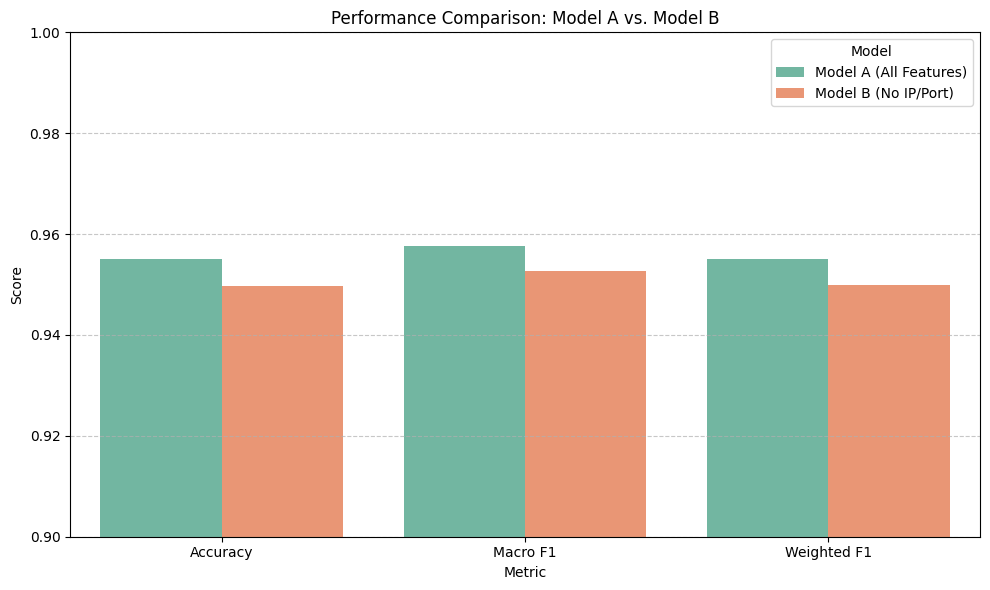

In [24]:
# Plot comparison of predictive performance metrics
plot_data = pd.melt(comparison_df.iloc[:3], id_vars=['Metric'], var_name='Model', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value', hue='Model', data=plot_data, palette='Set2')
plt.ylim(0.9, 1.0)
plt.title('Performance Comparison: Model A vs. Model B')
plt.ylabel('Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# EXPERIMENT 3: MI TOP-K FEATURE SELECTION
# UAVIDS-2025
# ==========================================
import pandas as pd
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

# Ensure preceding cells defining X_train_B and y_train are run first!
X_mi = X_train_B.copy()

cat_cols = X_mi.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = X_mi.select_dtypes(
    include=["number"]
).columns.tolist()

# Impute numerical features
num_imputer = SimpleImputer(strategy="median")

if num_cols:
    X_mi[num_cols] = num_imputer.fit_transform(
        X_mi[num_cols]
    )

# Encode categorical features
if cat_cols:
    cat_imputer = SimpleImputer(strategy="most_frequent")
    X_cat = cat_imputer.fit_transform(X_mi[cat_cols])

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_mi[cat_cols] = encoder.fit_transform(X_cat)

# Calculate MI scores
discrete_mask = [
    col in cat_cols for col in X_mi.columns
]

mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=42,
    n_jobs=-1
)

# Feature ranking
mi_ranking = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI_Score": mi_scores
}).sort_values(
    "MI_Score",
    ascending=False
).reset_index(drop=True)

print("MUTUAL INFORMATION FEATURE RANKING")
print(mi_ranking.to_string(index=False))

MUTUAL INFORMATION FEATURE RANKING
        Feature  MI_Score
   TxByteRate/s  1.052617
 FlowDuration/s  1.039362
 TxPacketRate/s  1.011205
Throughput/Kbps  0.921005
   RxByteRate/s  0.920565
 RxPacketRate/s  0.904189
        TxBytes  0.891175
 PacketDropRate  0.885631
        RxBytes  0.775995
      TxPackets  0.636472
      RxPackets  0.551806
AverageHopCount  0.495322
   MeanJitter/s  0.434836
    MeanDelay/s  0.337830
 MeanPacketSize  0.303548
    LostPackets  0.299634
       Protocol  0.000000


In [ ]:

# ==========================================
# EXPERIMENT 3: MI TOP-K FEATURE SELECTION
# UAVIDS-2025
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time
import numpy as np

# Feature subsets
top_k_values = [5, 10, 15]

mi_results = []

mi_models = {}

for k in top_k_values:

    print(f"\n{'='*45}")
    print(f"TRAINING MI TOP-{k} MODEL")
    print(f"{'='*45}")

    # Select top K features
    selected_features = mi_ranking["Feature"].head(k).tolist()

    X_train_k = X_train_B[selected_features].copy()
    X_test_k = X_test_B[selected_features].copy()

    # Identify data types
    cat_k = X_train_k.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    num_k = X_train_k.select_dtypes(
        include=["number"]
    ).columns.tolist()

    # Preprocessing
    transformers = []

    if num_k:
        transformers.append(
            ("num", SimpleImputer(strategy="median"), num_k)
        )

    if cat_k:
        cat_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])

        transformers.append(
            ("cat", cat_pipeline, cat_k)
        )

    preprocessor_k = ColumnTransformer(transformers)

    # Extra Trees model
    model_k = Pipeline([
        ("preprocessor", preprocessor_k),
        ("classifier", ExtraTreesClassifier(
            n_estimators=150,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Training
    start = time.perf_counter()

    model_k.fit(X_train_k, y_train)

    train_time = time.perf_counter() - start

    # Prediction
    start = time.perf_counter()

    y_pred_k = model_k.predict(X_test_k)

    inference_time = time.perf_counter() - start

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred_k)

    macro_f1 = f1_score(
        y_test, y_pred_k, average="macro"
    )

    weighted_f1 = f1_score(
        y_test, y_pred_k, average="weighted"
    )

    mi_results.append({
        "Experiment": f"MI Top-{k}",
        "Feature_Count": k,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Training_Time": train_time,
        "Inference_Time": inference_time
    })

    mi_models[k] = model_k

    print("Selected features:", selected_features)
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))
    print("Training Time:", round(train_time, 4))
    print("Inference Time:", round(inference_time, 4))

# Final result table
mi_results_df = pd.DataFrame(mi_results)

print("\n\nFINAL MI FEATURE SELECTION RESULTS")
print(mi_results_df.round(4).to_string(index=False))



TRAINING MI TOP-5 MODEL
Selected features: ['TxByteRate/s', 'FlowDuration/s', 'TxPacketRate/s', 'Throughput/Kbps', 'RxByteRate/s']
Accuracy: 0.9387
Macro F1: 0.9421
Weighted F1: 0.9388
Training Time: 11.2412
Inference Time: 0.7254

TRAINING MI TOP-10 MODEL
Selected features: ['TxByteRate/s', 'FlowDuration/s', 'TxPacketRate/s', 'Throughput/Kbps', 'RxByteRate/s', 'RxPacketRate/s', 'TxBytes', 'PacketDropRate', 'RxBytes', 'TxPackets']
Accuracy: 0.9434
Macro F1: 0.9464
Weighted F1: 0.9433
Training Time: 10.7753
Inference Time: 1.1444

TRAINING MI TOP-15 MODEL
Selected features: ['TxByteRate/s', 'FlowDuration/s', 'TxPacketRate/s', 'Throughput/Kbps', 'RxByteRate/s', 'RxPacketRate/s', 'TxBytes', 'PacketDropRate', 'RxBytes', 'TxPackets', 'RxPackets', 'AverageHopCount', 'MeanJitter/s', 'MeanDelay/s', 'MeanPacketSize']
Accuracy: 0.9495
Macro F1: 0.9525
Weighted F1: 0.9496
Training Time: 10.6002
Inference Time: 0.6493


FINAL MI FEATURE SELECTION RESULTS
Experiment  Feature_Count  Accuracy  Macro

In [ ]:
# ==========================================
# EXPERIMENT 4: EXTRA TREES FEATURE IMPORTANCE
# ==========================================

# সরাসরি ট্রেইনড model_B থেকে ফিচার ইম্পর্ট্যান্স মানগুলো নেওয়া হচ্ছে
importance_values = model_B.feature_importances_

# X_train_B এর কলাম নামের সাথে গুরুত্বের মানগুলো ম্যাপ করে একটি ডেটাফ্রেম তৈরি করা হচ্ছে
et_ranking = pd.DataFrame({
    "Feature": X_train_B.columns,
    "Importance": importance_values
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# র‍্যাংকিং প্রিন্ট করা হচ্ছে
print("EXTRA TREES FEATURE IMPORTANCE RANKING")
print(et_ranking.to_string(index=False))

print("\nTotal importance:", round(et_ranking["Importance"].sum(), 6))

EXTRA TREES FEATURE IMPORTANCE RANKING
        Feature  Importance
 PacketDropRate    0.168422
 FlowDuration/s    0.125130
 MeanPacketSize    0.117385
        RxBytes    0.067774
    LostPackets    0.054875
        TxBytes    0.054382
      TxPackets    0.052293
      RxPackets    0.049919
   RxByteRate/s    0.048772
Throughput/Kbps    0.047926
 TxPacketRate/s    0.046197
   TxByteRate/s    0.045839
 RxPacketRate/s    0.045405
   MeanJitter/s    0.027398
    MeanDelay/s    0.024877
AverageHopCount    0.023406
       Protocol    0.000000

Total importance: 1.0


In [ ]:
# ==========================================
# EXPERIMENT 4: EXTRA TREES FEATURE IMPORTANCE
# ==========================================

# Get feature importances directly from the trained model_B
importance_values = model_B.feature_importances_

# Map importances directly to the features in X_train_B
et_ranking = pd.DataFrame({
    "Feature": X_train_B.columns,
    "Importance": importance_values
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print("EXTRA TREES FEATURE IMPORTANCE RANKING")
print(et_ranking.to_string(index=False))

print("\nTotal importance:",
      round(et_ranking["Importance"].sum(), 6))

EXTRA TREES FEATURE IMPORTANCE RANKING
        Feature  Importance
 PacketDropRate    0.168422
 FlowDuration/s    0.125130
 MeanPacketSize    0.117385
        RxBytes    0.067774
    LostPackets    0.054875
        TxBytes    0.054382
      TxPackets    0.052293
      RxPackets    0.049919
   RxByteRate/s    0.048772
Throughput/Kbps    0.047926
 TxPacketRate/s    0.046197
   TxByteRate/s    0.045839
 RxPacketRate/s    0.045405
   MeanJitter/s    0.027398
    MeanDelay/s    0.024877
AverageHopCount    0.023406
       Protocol    0.000000

Total importance: 1.0


In [ ]:

# ==========================================
# EXPERIMENT 5: EXTRA TREES TOP-K SELECTION
# ==========================================

et_results = []
et_models = {}

top_k_values = [5, 10, 15]

for k in top_k_values:

    print("\n" + "=" * 45)
    print(f"TRAINING ET TOP-{k} MODEL")
    print("=" * 45)

    # Select Top-K features
    selected_features = (
        et_ranking["Feature"].head(k).tolist()
    )

    X_train_k = X_train_B[selected_features].copy()
    X_test_k = X_test_B[selected_features].copy()

    # Identify feature types
    cat_k = X_train_k.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    num_k = X_train_k.select_dtypes(
        include=["number"]
    ).columns.tolist()

    transformers = []

    if num_k:
        transformers.append(
            ("num",
             SimpleImputer(strategy="median"),
             num_k)
        )

    if cat_k:
        cat_pipeline = Pipeline([
            ("imputer",
             SimpleImputer(strategy="most_frequent")),
            ("encoder",
             OneHotEncoder(handle_unknown="ignore"))
        ])

        transformers.append(
            ("cat", cat_pipeline, cat_k)
        )

    preprocessor_k = ColumnTransformer(transformers)

    model_k = Pipeline([
        ("preprocessor", preprocessor_k),
        ("classifier", ExtraTreesClassifier(
            n_estimators=150,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Training
    start = time.perf_counter()

    model_k.fit(X_train_k, y_train)

    train_time = time.perf_counter() - start

    # Prediction
    start = time.perf_counter()

    y_pred_k = model_k.predict(X_test_k)

    inference_time = time.perf_counter() - start

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred_k)

    macro_f1 = f1_score(
        y_test, y_pred_k, average="macro"
    )

    weighted_f1 = f1_score(
        y_test, y_pred_k, average="weighted"
    )

    et_results.append({
        "Experiment": f"ET Top-{k}",
        "Feature_Count": k,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Training_Time": train_time,
        "Inference_Time": inference_time
    })

    et_models[k] = model_k

    print("Selected features:", selected_features)
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))
    print("Training Time:", round(train_time, 4))
    print("Inference Time:", round(inference_time, 4))


# Final results
et_results_df = pd.DataFrame(et_results)

print("\nEXTRA TREES FEATURE SELECTION RESULTS")
print(et_results_df.round(4).to_string(index=False))



TRAINING ET TOP-5 MODEL
Selected features: ['PacketDropRate', 'FlowDuration/s', 'MeanPacketSize', 'RxBytes', 'LostPackets']
Accuracy: 0.9418
Macro F1: 0.9447
Weighted F1: 0.9418
Training Time: 8.3944
Inference Time: 1.122

TRAINING ET TOP-10 MODEL
Selected features: ['PacketDropRate', 'FlowDuration/s', 'MeanPacketSize', 'RxBytes', 'LostPackets', 'TxBytes', 'TxPackets', 'RxPackets', 'RxByteRate/s', 'Throughput/Kbps']
Accuracy: 0.943
Macro F1: 0.946
Weighted F1: 0.9429
Training Time: 8.9996
Inference Time: 0.6111

TRAINING ET TOP-15 MODEL
Selected features: ['PacketDropRate', 'FlowDuration/s', 'MeanPacketSize', 'RxBytes', 'LostPackets', 'TxBytes', 'TxPackets', 'RxPackets', 'RxByteRate/s', 'Throughput/Kbps', 'TxPacketRate/s', 'TxByteRate/s', 'RxPacketRate/s', 'MeanJitter/s', 'MeanDelay/s']
Accuracy: 0.9462
Macro F1: 0.9494
Weighted F1: 0.9463
Training Time: 12.4261
Inference Time: 0.6558

EXTRA TREES FEATURE SELECTION RESULTS
Experiment  Feature_Count  Accuracy  Macro_F1  Weighted_F1  Tr

In [ ]:

# ==========================================
# EXPERIMENT 6: COMBINED FEATURE RANKING
# MI + EXTRA TREES
# ==========================================

# Copy rankings
mi_rank = mi_ranking[["Feature"]].copy()
et_rank = et_ranking[["Feature"]].copy()

# Assign ranks
mi_rank["MI_Rank"] = range(1, len(mi_rank) + 1)
et_rank["ET_Rank"] = range(1, len(et_rank) + 1)

# Merge rankings
combined_ranking = mi_rank.merge(
    et_rank,
    on="Feature"
)

# Average Rank
combined_ranking["Average_Rank"] = (
    combined_ranking["MI_Rank"] +
    combined_ranking["ET_Rank"]
) / 2

# Sort by average rank
combined_ranking = combined_ranking.sort_values(
    "Average_Rank"
).reset_index(drop=True)

print("COMBINED FEATURE RANKING")
print(combined_ranking.to_string(index=False))


COMBINED FEATURE RANKING
        Feature  MI_Rank  ET_Rank  Average_Rank
 FlowDuration/s        2        2           2.0
 PacketDropRate        8        1           4.5
        TxBytes        7        6           6.5
   TxByteRate/s        1       12           6.5
        RxBytes        9        4           6.5
Throughput/Kbps        4       10           7.0
   RxByteRate/s        5        9           7.0
 TxPacketRate/s        3       11           7.0
      TxPackets       10        7           8.5
 MeanPacketSize       15        3           9.0
 RxPacketRate/s        6       13           9.5
      RxPackets       11        8           9.5
    LostPackets       16        5          10.5
   MeanJitter/s       13       14          13.5
AverageHopCount       12       16          14.0
    MeanDelay/s       14       15          14.5
       Protocol       17       17          17.0


In [ ]:

# ==========================================
# EXPERIMENT 7: COMBINED TOP-K FEATURE SELECTION
# MI + EXTRA TREES
# ==========================================

combined_results = []
combined_models = {}

top_k_values = [5, 10, 15]

for k in top_k_values:

    print("\n" + "=" * 45)
    print(f"TRAINING COMBINED TOP-{k} MODEL")
    print("=" * 45)

    # Select Top-K features
    selected_features = (
        combined_ranking["Feature"].head(k).tolist()
    )

    X_train_k = X_train_B[selected_features].copy()
    X_test_k = X_test_B[selected_features].copy()

    # Identify feature types
    cat_k = X_train_k.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    num_k = X_train_k.select_dtypes(
        include=["number"]
    ).columns.tolist()

    transformers = []

    if num_k:
        transformers.append(
            ("num", SimpleImputer(strategy="median"), num_k)
        )

    if cat_k:
        cat_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])

        transformers.append(
            ("cat", cat_pipeline, cat_k)
        )

    preprocessor_k = ColumnTransformer(transformers)

    model_k = Pipeline([
        ("preprocessor", preprocessor_k),
        ("classifier", ExtraTreesClassifier(
            n_estimators=150,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Training
    start = time.perf_counter()

    model_k.fit(X_train_k, y_train)

    train_time = time.perf_counter() - start

    # Prediction
    start = time.perf_counter()

    y_pred_k = model_k.predict(X_test_k)

    inference_time = time.perf_counter() - start

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred_k)

    macro_f1 = f1_score(
        y_test, y_pred_k, average="macro"
    )

    weighted_f1 = f1_score(
        y_test, y_pred_k, average="weighted"
    )

    combined_results.append({
        "Experiment": f"Combined Top-{k}",
        "Feature_Count": k,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Training_Time": train_time,
        "Inference_Time": inference_time
    })

    combined_models[k] = model_k

    print("Selected features:", selected_features)
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))
    print("Training Time:", round(train_time, 4))
    print("Inference Time:", round(inference_time, 4))


# Final results
combined_results_df = pd.DataFrame(combined_results)

print("\nCOMBINED FEATURE SELECTION RESULTS")
print(combined_results_df.round(4).to_string(index=False))



TRAINING COMBINED TOP-5 MODEL
Selected features: ['FlowDuration/s', 'PacketDropRate', 'TxBytes', 'TxByteRate/s', 'RxBytes']
Accuracy: 0.9284
Macro F1: 0.9315
Weighted F1: 0.9281
Training Time: 8.3139
Inference Time: 0.7035

TRAINING COMBINED TOP-10 MODEL
Selected features: ['FlowDuration/s', 'PacketDropRate', 'TxBytes', 'TxByteRate/s', 'RxBytes', 'Throughput/Kbps', 'RxByteRate/s', 'TxPacketRate/s', 'TxPackets', 'MeanPacketSize']
Accuracy: 0.9441
Macro F1: 0.9472
Weighted F1: 0.9441
Training Time: 10.734
Inference Time: 0.6178

TRAINING COMBINED TOP-15 MODEL
Selected features: ['FlowDuration/s', 'PacketDropRate', 'TxBytes', 'TxByteRate/s', 'RxBytes', 'Throughput/Kbps', 'RxByteRate/s', 'TxPacketRate/s', 'TxPackets', 'MeanPacketSize', 'RxPacketRate/s', 'RxPackets', 'LostPackets', 'MeanJitter/s', 'AverageHopCount']
Accuracy: 0.9483
Macro F1: 0.9513
Weighted F1: 0.9483
Training Time: 12.3744
Inference Time: 0.6354

COMBINED FEATURE SELECTION RESULTS
     Experiment  Feature_Count  Accuracy

In [ ]:

# ==========================================
# MASTER EXPERIMENTAL RESULTS
# UAVIDS-2025
# ==========================================

baseline_results = pd.DataFrame([
    {
        "Experiment": "Baseline A",
        "Method": "Full Features",
        "Features": 20,
        "Accuracy": 0.9550,
        "Macro_F1": 0.9577,
        "Weighted_F1": 0.9550,
        "Training_Time": 15.4328,
        "Inference_Time": 1.7801
    },
    {
        "Experiment": "Baseline B",
        "Method": "Behavior Only",
        "Features": 17,
        "Accuracy": 0.9497,
        "Macro_F1": 0.9527,
        "Weighted_F1": 0.9498,
        "Training_Time": 14.7488,
        "Inference_Time": 0.5916
    }
])

def standardize_results(df, method):
    result = df.copy()

    result = result.rename(columns={
        "Feature_Count": "Features",
        "Accuracy": "Accuracy",
        "Macro_F1": "Macro_F1",
        "Weighted_F1": "Weighted_F1",
        "Training_Time": "Training_Time",
        "Inference_Time": "Inference_Time"
    })

    result["Method"] = method

    return result[
        ["Experiment", "Method", "Features",
         "Accuracy", "Macro_F1", "Weighted_F1",
         "Training_Time", "Inference_Time"]
    ]

mi_master = standardize_results(mi_results_df, "MI")
et_master = standardize_results(et_results_df, "Extra Trees")
combined_master = standardize_results(
    combined_results_df, "Combined"
)

master_results = pd.concat(
    [
        baseline_results,
        mi_master,
        et_master,
        combined_master
    ],
    ignore_index=True
)

master_results = master_results.sort_values(
    "Macro_F1", ascending=False
).reset_index(drop=True)

print("MASTER EXPERIMENTAL RESULTS")
print(master_results.round(4).to_string(index=False))

# Save results
master_results.to_csv(
    "UAVIDS_Master_Experimental_Results.csv",
    index=False
)

print("\nResults saved successfully.")


MASTER EXPERIMENTAL RESULTS
     Experiment        Method  Features  Accuracy  Macro_F1  Weighted_F1  Training_Time  Inference_Time
     Baseline A Full Features        20    0.9550    0.9577       0.9550        15.4328          1.7801
     Baseline B Behavior Only        17    0.9497    0.9527       0.9498        14.7488          0.5916
      MI Top-15            MI        15    0.9495    0.9525       0.9496        10.6002          0.6493
Combined Top-15      Combined        15    0.9483    0.9513       0.9483        12.3744          0.6354
      ET Top-15   Extra Trees        15    0.9462    0.9494       0.9463        12.4261          0.6558
Combined Top-10      Combined        10    0.9441    0.9472       0.9441        10.7340          0.6178
      MI Top-10            MI        10    0.9434    0.9464       0.9433        10.7753          1.1444
      ET Top-10   Extra Trees        10    0.9430    0.9460       0.9429         8.9996          0.6111
       ET Top-5   Extra Trees       

In [ ]:
# ==========================================
# FINAL INDEPENDENT EVALUATION
# STEP 1: NEW DATA SPLIT
# ==========================================

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Define X_B by dropping IP/Port features from original X
exclude_cols_B = ['SrcPort', 'SrcAddr', 'DstAddr']
X_B = X.drop(columns=[col for col in exclude_cols_B if col in X.columns])

# Verify original row alignment
assert X_B.index.equals(y.index), (
    "ERROR: X_B and y indices do not match!"
)

# 70% Training, 30% Temporary
X_final_train, X_temp, y_final_train, y_temp = train_test_split(
    X_B,
    y,
    test_size=0.30,
    random_state=2026,
    stratify=y
)

# 15% Validation, 15% Final Test
X_final_val, X_final_test, y_final_val, y_final_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=2026,
    stratify=y_temp
)

print("=" * 45)
print("FINAL INDEPENDENT DATA SPLIT")
print("=" * 45)

print("Training:", X_final_train.shape)
print("Validation:", X_final_val.shape)
print("Final Test:", X_final_test.shape)

print("\nClass distribution:")

print("\nTraining:")
print(y_final_train.value_counts(normalize=True).round(4))

print("\nValidation:")
print(y_final_val.value_counts(normalize=True).round(4))

print("\nFinal Test:")
print(y_final_test.value_counts(normalize=True).round(4))

print("\nData split completed successfully.")



# ==========================================
# FINAL SPLIT VERIFICATION
# ==========================================

print("\nFINAL VERIFICATION")
print("=" * 45)

print("Total features:", X_B.shape[1])
print("Total records:", len(X_B))

print("Training records:", len(X_final_train))
print("Validation records:", len(X_final_val))
print("Test records:", len(X_final_test))

print("Index overlap (Train-Val):",
      len(set(X_final_train.index) & set(X_final_val.index)))

print("Index overlap (Train-Test):",
      len(set(X_final_train.index) & set(X_final_test.index)))

print("Index overlap (Val-Test):",
      len(set(X_final_val.index) & set(X_final_test.index)))

assert X_B.shape[1] == 17
assert len(set(X_final_train.index) & set(X_final_val.index)) == 0
assert len(set(X_final_train.index) & set(X_final_test.index)) == 0
assert len(set(X_final_val.index) & set(X_final_test.index)) == 0

print("\nAll verification checks passed!")


FINAL INDEPENDENT DATA SPLIT
Training: (85519, 17)
Validation: (18326, 17)
Final Test: (18326, 17)

Class distribution:

Training:
label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1971
Flooding Attack     0.1615
Name: proportion, dtype: float64

Validation:
label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1970
Flooding Attack     0.1615
Name: proportion, dtype: float64

Final Test:
label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1971
Flooding Attack     0.1615
Name: proportion, dtype: float64

Data split completed successfully.

FINAL VERIFICATION
Total features: 17
Total records: 122171
Training records: 85519
Validation records: 18326
Test records: 18326
Index overlap (Train-Val): 0
Index overlap (Train-Test): 0
Index overlap (Val-Test): 0

All verification checks passed!


### 5-Fold Stratified Cross-Validation on Final Training Set
To test the stability and prevent any data leakage, we perform 5-fold Stratified Cross-Validation strictly on the Training Set (`X_final_train`, `y_final_train`) using our 17 behavioral features.

In [27]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
import numpy as np
import pandas as pd

# Ensure we safely load variables from previous steps
# If X_final_train is not yet defined in active memory, we reconstruct it
if 'X_final_train' not in globals():
    print("Reconstructing final splits for safety...")
    exclude_cols_B = ['SrcPort', 'SrcAddr', 'DstAddr']
    X_B_safe = X.drop(columns=[col for col in exclude_cols_B if col in X.columns])
    from sklearn.model_selection import train_test_split
    X_final_train, X_temp, y_final_train, y_temp = train_test_split(
        X_B_safe, y, test_size=0.30, random_state=2026, stratify=y
    )

# 1. Prepare preprocessing pipeline
cat_cols = X_final_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = X_final_train.select_dtypes(include=["number"]).columns.tolist()

transformers = []
if num_cols:
    transformers.append(("num", SimpleImputer(strategy="median"), num_cols))
if cat_cols:
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(("cat", cat_pipe, cat_cols))

preprocessor_cv = ColumnTransformer(transformers)

# Define multiple random seeds to evaluate model robustness
seeds = [42, 100, 2026]
all_seed_results = {}

for seed in seeds:
    print(f"\nExecuting 5-Fold Cross-Validation with Random Seed: {seed}...")

    cv_pipeline = Pipeline([
        ("preprocessor", preprocessor_cv),
        ("classifier", ExtraTreesClassifier(n_estimators=150, random_state=seed, n_jobs=-1))
    ])

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    scores = cross_val_score(cv_pipeline, X_final_train, y_final_train, cv=skf, scoring='accuracy', n_jobs=-1)

    all_seed_results[seed] = scores

    print(f"Seed {seed} Fold Accuracies: {['{:.4f}'.format(x) for x in scores]}")
    print(f"Seed {seed} Mean Accuracy: {np.mean(scores):.4f} (± {np.std(scores):.4f})")

# Aggregate summary
print("\n" + "="*50)
print("SUMMARY ACROSS MULTIPLE SEEDS")
print("="*50)
overall_means = []
for seed, scores in all_seed_results.items():
    mean_score = np.mean(scores)
    overall_means.append(mean_score)
    print(f"Seed {seed:4d} | Mean CV Accuracy: {mean_score:.4f} (Std: {np.std(scores):.4f})")

print(f"\nGrand Mean CV Accuracy: {np.mean(overall_means):.4f}")

Reconstructing final splits for safety...

Executing 5-Fold Cross-Validation with Random Seed: 42...
Seed 42 Fold Accuracies: ['0.9491', '0.9475', '0.9450', '0.9486', '0.9491']
Seed 42 Mean Accuracy: 0.9478 (± 0.0015)

Executing 5-Fold Cross-Validation with Random Seed: 100...
Seed 100 Fold Accuracies: ['0.9481', '0.9476', '0.9474', '0.9474', '0.9464']
Seed 100 Mean Accuracy: 0.9474 (± 0.0006)

Executing 5-Fold Cross-Validation with Random Seed: 2026...
Seed 2026 Fold Accuracies: ['0.9457', '0.9496', '0.9459', '0.9518', '0.9457']
Seed 2026 Mean Accuracy: 0.9477 (± 0.0025)

SUMMARY ACROSS MULTIPLE SEEDS
Seed   42 | Mean CV Accuracy: 0.9478 (Std: 0.0015)
Seed  100 | Mean CV Accuracy: 0.9474 (Std: 0.0006)
Seed 2026 | Mean CV Accuracy: 0.9477 (Std: 0.0025)

Grand Mean CV Accuracy: 0.9477


### Repeated Stratified 5-Fold Cross-Validation
To perform a rigorous statistical evaluation, we run a Repeated Stratified 5-Fold Cross-Validation (5 Folds repeated 3 times, yielding 15 total fits) on our training set.

In [28]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
import numpy as np

# Prepare preprocessing pipeline dynamically based on active X_final_train
cat_cols = X_final_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = X_final_train.select_dtypes(include=["number"]).columns.tolist()

transformers = []
if num_cols:
    transformers.append(("num", SimpleImputer(strategy="median"), num_cols))
if cat_cols:
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(("cat", cat_pipe, cat_cols))

preprocessor_cv = ColumnTransformer(transformers)

# Define the pipeline
repeated_cv_pipeline = Pipeline([
    ("preprocessor", preprocessor_cv),
    ("classifier", ExtraTreesClassifier(n_estimators=150, random_state=42, n_jobs=-1))
])

# Configure Repeated Stratified K-Fold (5 folds, 3 repeats)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

print("Executing Repeated Stratified 5-Fold Cross-Validation (15 total fits)...")
repeated_scores = cross_val_score(repeated_cv_pipeline, X_final_train, y_final_train, cv=rskf, scoring='accuracy', n_jobs=-1)

print("\n--- Repeated CV Accuracy Scores ---")
for idx, score in enumerate(repeated_scores):
    print(f"Run {idx//5 + 1} - Fold {idx%5 + 1}: {score:.4f}")

print(f"\nOverall Mean CV Accuracy: {np.mean(repeated_scores):.4f}")
print(f"Overall Standard Deviation: {np.std(repeated_scores):.4f}")

Executing Repeated Stratified 5-Fold Cross-Validation (15 total fits)...

--- Repeated CV Accuracy Scores ---
Run 1 - Fold 1: 0.9491
Run 1 - Fold 2: 0.9475
Run 1 - Fold 3: 0.9450
Run 1 - Fold 4: 0.9486
Run 1 - Fold 5: 0.9491
Run 2 - Fold 1: 0.9488
Run 2 - Fold 2: 0.9481
Run 2 - Fold 3: 0.9476
Run 2 - Fold 4: 0.9457
Run 2 - Fold 5: 0.9488
Run 3 - Fold 1: 0.9494
Run 3 - Fold 2: 0.9477
Run 3 - Fold 3: 0.9451
Run 3 - Fold 4: 0.9477
Run 3 - Fold 5: 0.9472

Overall Mean CV Accuracy: 0.9477
Overall Standard Deviation: 0.0014


In [29]:

# ==========================================
# FINAL EVALUATION: STEP 2A
# MUTUAL INFORMATION RANKING
# ==========================================

from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
import pandas as pd
import numpy as np

X_mi_final = X_final_train.copy()

cat_cols = X_mi_final.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = X_mi_final.select_dtypes(
    include=["number"]
).columns.tolist()

# Numerical imputation: fit on training only
num_imputer_final = SimpleImputer(strategy="median")

if num_cols:
    X_mi_final[num_cols] = num_imputer_final.fit_transform(
        X_mi_final[num_cols]
    )

# Categorical imputation and encoding
if cat_cols:
    cat_imputer_final = SimpleImputer(
        strategy="most_frequent"
    )

    X_cat_final = cat_imputer_final.fit_transform(
        X_mi_final[cat_cols]
    )

    encoder_final = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_mi_final[cat_cols] = encoder_final.fit_transform(
        X_cat_final
    )

# Discrete feature identification
discrete_mask_final = [
    col in cat_cols for col in X_mi_final.columns
]

# Calculate MI
mi_scores_final = mutual_info_classif(
    X_mi_final,
    y_final_train,
    discrete_features=discrete_mask_final,
    random_state=42,
    n_jobs=-1
)

# Create ranking
mi_ranking_final = pd.DataFrame({
    "Feature": X_mi_final.columns,
    "MI_Score": mi_scores_final
}).sort_values(
    "MI_Score",
    ascending=False
).reset_index(drop=True)

print("FINAL TRAINING DATA: MI RANKING")
print(mi_ranking_final.to_string(index=False))


FINAL TRAINING DATA: MI RANKING
        Feature  MI_Score
   TxByteRate/s  1.044358
 FlowDuration/s  1.025120
 TxPacketRate/s  1.002867
Throughput/Kbps  0.912732
   RxByteRate/s  0.911509
 RxPacketRate/s  0.892596
        TxBytes  0.890491
 PacketDropRate  0.874106
        RxBytes  0.778424
      TxPackets  0.639780
      RxPackets  0.550600
AverageHopCount  0.496226
   MeanJitter/s  0.426038
    MeanDelay/s  0.327885
 MeanPacketSize  0.302339
    LostPackets  0.297208
       Protocol  0.000000


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np
import time

# Ensure final splits are loaded for safety
if 'X_final_val' not in globals() or 'X_final_train' not in globals():
    print("Reconstructing final splits for safety...")
    exclude_cols_B = ['SrcPort', 'SrcAddr', 'DstAddr']
    X_B_safe = X.drop(columns=[col for col in exclude_cols_B if col in X.columns])
    X_final_train, X_temp, y_final_train, y_temp = train_test_split(
        X_B_safe, y, test_size=0.30, random_state=2026, stratify=y
    )
    X_final_val, X_final_test, y_final_val, y_final_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=2026, stratify=y_temp
    )

# ----------------------------------------------
# 1. Prepare feature types
# ----------------------------------------------
cat_cols = X_final_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = X_final_train.select_dtypes(
    include=["number"]
).columns.tolist()

def make_preprocessor(num_cols, cat_cols):
    transformers = []
    if num_cols:
        transformers.append((
            "num",
            SimpleImputer(strategy="median"),
            num_cols
        ))
    if cat_cols:
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])
        transformers.append((
            "cat", cat_pipe, cat_cols
        ))
    return ColumnTransformer(transformers)

# ----------------------------------------------
# 2. Train ET ranking model on training data
# ----------------------------------------------
ranking_model = Pipeline([
    ("preprocessor", make_preprocessor(num_cols, cat_cols)),
    ("classifier", ExtraTreesClassifier(n_estimators=150, random_state=42, n_jobs=-1))
])
ranking_model.fit(X_final_train, y_final_train)

classifier = ranking_model.named_steps["classifier"]
encoded_names = ranking_model.named_steps["preprocessor"].get_feature_names_out()

# Aggregate encoded features to original features
importance_df = pd.DataFrame({
    "Encoded_Feature": encoded_names,
    "Importance": classifier.feature_importances_
})

def original_feature(name):
    if name.startswith("num__"):
        return name.replace("num__", "", 1)
    if name.startswith("cat__"):
        remaining = name.replace("cat__", "", 1)
        matches = [
            c for c in cat_cols
            if remaining == c or remaining.startswith(c + "_")
        ]
        if matches:
            return max(matches, key=len)
    return name

importance_df["Feature"] = importance_df["Encoded_Feature"].apply(original_feature)

et_ranking_final = (
    importance_df.groupby("Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("FINAL EXTRA TREES RANKING")
print(et_ranking_final.to_string(index=False))

# ----------------------------------------------
# 3. Create Combined Ranking
# ----------------------------------------------
mi_rank = mi_ranking_final[["Feature"]].copy()
et_rank = et_ranking_final[["Feature"]].copy()

mi_rank["MI_Rank"] = range(1, len(mi_rank) + 1)
et_rank["ET_Rank"] = range(1, len(et_rank) + 1)

combined_ranking_final = mi_rank.merge(et_rank, on="Feature")
combined_ranking_final["Average_Rank"] = (combined_ranking_final["MI_Rank"] + combined_ranking_final["ET_Rank"]) / 2
combined_ranking_final = combined_ranking_final.sort_values("Average_Rank").reset_index(drop=True)

print("\nFINAL COMBINED RANKING")
print(combined_ranking_final.to_string(index=False))

# ----------------------------------------------
# 4. Validation evaluation
# ----------------------------------------------
rankings = {
    "MI": mi_ranking_final["Feature"].tolist(),
    "ET": et_ranking_final["Feature"].tolist(),
    "Combined": combined_ranking_final["Feature"].tolist()
}

validation_results = []
validation_models = {}
candidate_sets = {
    "Baseline B": X_final_train.columns.tolist()
}

for method, features in rankings.items():
    for k in [5, 10, 15]:
        candidate_sets[f"{method} Top-{k}"] = features[:k]

for name, features in candidate_sets.items():
    Xtr = X_final_train[features].copy()
    Xval = X_final_val[features].copy()

    cats = Xtr.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    nums = Xtr.select_dtypes(include=["number"]).columns.tolist()

    model = Pipeline([
        ("preprocessor", make_preprocessor(nums, cats)),
        ("classifier", ExtraTreesClassifier(n_estimators=150, random_state=42, n_jobs=-1))
    ])

    start = time.perf_counter()
    model.fit(Xtr, y_final_train)
    train_time = time.perf_counter() - start

    predictions = model.predict(Xval)
    accuracy = accuracy_score(y_final_val, predictions)
    macro = f1_score(y_final_val, predictions, average="macro")
    weighted = f1_score(y_final_val, predictions, average="weighted")

    validation_results.append({
        "Experiment": name,
        "Features": len(features),
        "Accuracy": accuracy,
        "Macro_F1": macro,
        "Weighted_F1": weighted,
        "Training_Time": train_time
    })
    validation_models[name] = model

validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True)

print("\n" + "=" * 65)
print("FINAL VALIDATION COMPARISON")
print("=" * 65)
print(validation_df.round(4).to_string(index=False))

best_candidate = validation_df.iloc[0]
print("\nBEST VALIDATION CANDIDATE")
print(best_candidate.to_string())

Reconstructing final splits for safety...
FINAL EXTRA TREES RANKING
        Feature  Importance
 PacketDropRate    0.176433
 MeanPacketSize    0.117497
 FlowDuration/s    0.115007
        RxBytes    0.058968
    LostPackets    0.057346
      RxPackets    0.056483
        TxBytes    0.055692
      TxPackets    0.053727
Throughput/Kbps    0.048559
 RxPacketRate/s    0.047795
   TxByteRate/s    0.047625
 TxPacketRate/s    0.046267
   RxByteRate/s    0.044890
    MeanDelay/s    0.025609
   MeanJitter/s    0.025035
AverageHopCount    0.023066
       Protocol    0.000000

FINAL COMBINED RANKING
        Feature  MI_Rank  ET_Rank  Average_Rank
 FlowDuration/s        2        3           2.5
 PacketDropRate        8        1           4.5
   TxByteRate/s        1       11           6.0
Throughput/Kbps        4        9           6.5
        RxBytes        9        4           6.5
        TxBytes        7        7           7.0
 TxPacketRate/s        3       12           7.5
 RxPacketRate/s     

In [34]:

# ==========================================
# FINAL INDEPENDENT TEST EVALUATION
# SELECTED MODEL: MI TOP-15
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import time

# 1. Selected features
selected_features = mi_ranking_final[
    "Feature"
].head(15).tolist()

# 2. Combine Training + Validation
X_train_final = pd.concat(
    [X_final_train, X_final_val]
)

y_train_final = pd.concat(
    [y_final_train, y_final_val]
)

# 3. Prepare final datasets
Xtr = X_train_final[selected_features].copy()
Xtest = X_final_test[selected_features].copy()

cat_cols = Xtr.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = Xtr.select_dtypes(
    include=["number"]
).columns.tolist()

transformers = []

if num_cols:
    transformers.append((
        "num",
        SimpleImputer(strategy="median"),
        num_cols
    ))

if cat_cols:
    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append((
        "cat", cat_pipeline, cat_cols
    ))

preprocessor = ColumnTransformer(transformers)

# 4. Final Model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ))
])

# 5. Training
start = time.perf_counter()

final_model.fit(Xtr, y_train_final)

final_training_time = time.perf_counter() - start

# 6. Independent Testing
start = time.perf_counter()

y_final_pred = final_model.predict(Xtest)

final_inference_time = time.perf_counter() - start

# 7. Final Metrics
final_accuracy = accuracy_score(
    y_final_test, y_final_pred
)

final_macro_f1 = f1_score(
    y_final_test, y_final_pred, average="macro"
)

final_weighted_f1 = f1_score(
    y_final_test, y_final_pred, average="weighted"
)

print("=" * 55)
print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 55)

print("Selected Features:", len(selected_features))
print("Accuracy:", round(final_accuracy, 4))
print("Macro F1:", round(final_macro_f1, 4))
print("Weighted F1:", round(final_weighted_f1, 4))
print("Training Time:", round(final_training_time, 4))
print("Inference Time:", round(final_inference_time, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_final_test,
    y_final_pred,
    digits=4
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(
    y_final_test,
    y_final_pred
))


FINAL INDEPENDENT TEST RESULTS
Selected Features: 15
Accuracy: 0.9489
Macro F1: 0.9519
Weighted F1: 0.949
Training Time: 12.4598
Inference Time: 1.0379

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Blackhole Attack     0.9133    0.8746    0.8936      3916
 Flooding Attack     0.9969    0.9922    0.9946      2959
  Normal Traffic     0.9873    0.9878    0.9875      3926
    Sybil Attack     0.9978    0.9989    0.9983      3612
 Wormhole Attack     0.8669    0.9054    0.8858      3913

        accuracy                         0.9489     18326
       macro avg     0.9524    0.9518    0.9519     18326
    weighted avg     0.9494    0.9489    0.9490     18326


CONFUSION MATRIX
[[3425    1    4    0  486]
 [   0 2936    0    7   16]
 [   9    0 3878    0   39]
 [   0    1    0 3608    3]
 [ 316    7   46    1 3543]]


In [37]:
# ==========================================
# FINAL INDEPENDENT BASELINE B EVALUATION
# 17 BEHAVIORAL FEATURES
# ==========================================

import time
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

# Use all 17 behavioral features
Xtr = X_train_final.copy()
Xtest = X_final_test.copy()

cat_cols = Xtr.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = Xtr.select_dtypes(
    include=["number"]
).columns.tolist()

transformers = []

if num_cols:
    transformers.append((
        "num",
        SimpleImputer(strategy="median"),
        num_cols
    ))

if cat_cols:
    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append((
        "cat", cat_pipeline, cat_cols
    ))

preprocessor = ColumnTransformer(transformers)

baseline_final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ))
])

# Training
start = time.perf_counter()

baseline_final_model.fit(
    Xtr, y_train_final
)

baseline_training_time = time.perf_counter() - start

# Independent testing
start = time.perf_counter()

baseline_pred = baseline_final_model.predict(Xtest)

baseline_inference_time = time.perf_counter() - start

# Metrics
print("FINAL BASELINE B RESULTS")
print("Features:", Xtr.shape[1])
print("Accuracy:", accuracy_score(y_final_test, baseline_pred))
print("Macro F1:", f1_score(
    y_final_test, baseline_pred, average="macro"
))
print("Weighted F1:", f1_score(
    y_final_test, baseline_pred, average="weighted"
))
print("Training Time:", baseline_training_time)
print("Inference Time:", baseline_inference_time)

FINAL BASELINE B RESULTS
Features: 17
Accuracy: 0.94799738077049
Macro F1: 0.9510447331708514
Weighted F1: 0.948055289982328
Training Time: 14.976882071000091
Inference Time: 0.5226268569999775
